In [1]:
# Rucno importovanje ssp modula:
import sys
sys.path.insert(0, '/home/emir/Faks/SIS2/Knjiga_SIS2/Prilozi/SIS2_Kodovi/')
import ssp

# Importovanje ostalih biblioteka:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# Podesavanje prikaza za knjigu:
ssp.FORMATIRANJE_PRIKAZA = "BOOK"
ssp.REZOLUCIJA = "LOW"

# Podesavanje prikaza za rad studenata:
# ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
# ssp.REZOLUCIJA = "LOW"

In [2]:
#Programski kod 7.1

In [3]:
# Parametri
trajanje = 150
dt = 0.01

greska_mjerenja = 0.3  # greška mjerenja pozicije
greska_ubrzanja = 0.2  # greška ubrzanja
a = np.array([[1, dt], [0, 1]])  # matrica prelaza
b = np.array([[dt**2 / 2], [dt]])  # matrica ulaza
c = np.array([1, 0])  # matrica mjerenja

In [4]:
#Programski kod 7.2

In [5]:
# Inicijalizacija stanja
x = np.array([[0], [0]])  # vektor početnog stanja
x_est = x  # početna estimacija stanja

# Kovarijansa greške mjerenja
Sz = greska_mjerenja**2
# Kovarijansa procesnog šuma
Sw = greska_ubrzanja**2 * np.array([[dt**4 / 4, dt**3 / 2],
                                    [dt**3 / 2, dt**2]])
P = Sw  # početna estimacija kovarijanse

In [6]:
#Programski kod 7.3

In [7]:
# Pomoćne varijable
pozicija = np.empty((1, 1))
pozicija_est = np.empty((1, 1))
pozicija_mjerena= np.empty((1, 1))
brzina = np.empty((1, 1))
brzina_est = np.empty((1, 1))

In [8]:
#Programski kod 7.4

In [9]:
# Glavna petlja
for t in np.linspace(0, trajanje, int(trajanje / dt)):
    # ulazni signal
    if (t<50):
        u = 0.1 
    elif (t<100):
        u = -0.1
    else:
        u = 0
    
    # Simulacija procesnog šuma:
    ProcesniShum = greska_ubrzanja * np.array([[(dt**2 / 2) * np.random.normal(0, 1)],
                                               [dt * np.random.normal(0, 1)]])
    x = a @ x + b * u + ProcesniShum
    
    # Simulacija mjernog šuma:
    MjerniShum = greska_mjerenja * np.random.normal(0, 1)
    y = c @ x + MjerniShum
    
    # Estimacija stanja
    x_est = a @ x_est + b * u
    # Inovacijski vektor
    Inn = y - c @ x_est
    
    # Računanje kovarijanse inovacije:
    s = c @ P @ c.T + Sz
    
    # Matrica Kalmanovog pojačanja:
    K = P @ c.T * (s**(-1))
    
    # Osvježavanje estimacije:
    x_est = x_est + K * Inn
    # Računanje kovarijanse greške estimacije
    P = (np.eye(2) - K @ c) @ P
    
    #print (x)
    
    # Varijable za prikaz
    pozicija = np.vstack((pozicija, x[0, 0]))
    pozicija_mjerena = np.vstack((pozicija_mjerena, y[0]))
    pozicija_est = np.vstack((pozicija_est, x_est[0, 0]))
    brzina = np.vstack((brzina, x[1, 0]))
    brzina_est = np.vstack((brzina_est, x_est[1, 0]))

In [10]:
#Programski kod 7.5

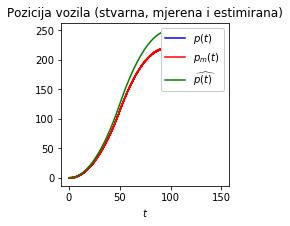

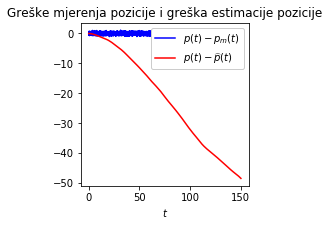

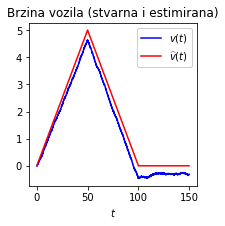

In [11]:
# Prikaz rezultata
t = np.linspace(0, trajanje, int(trajanje / dt))

ssp.slprom1D.grafik(t, pozicija[1:, :], t, pozicija_mjerena[1:, :], 
                    t, pozicija_est[1:, :],
                    naslov = 'Pozicija vozila (stvarna, mjerena i estimirana)',
                    legenda = ['$p(t)$', '$p_m(t)$', '$\widehat{p(t)}$'])

ssp.slprom1D.grafik(t, pozicija[1:, :] - pozicija_mjerena[1:, :], 
                    t, pozicija[1:, :] - pozicija_est[1:, :],
                    naslov = 'Greške mjerenja pozicije i greška estimacije pozicije',
                    legenda = ['$p(t)-p_m(t)$', '$p(t)-\widehat{p}(t)$'])

ssp.slprom1D.grafik(t, brzina[1:, :], t, brzina_est[1:, :],
                    naslov = 'Brzina vozila (stvarna i estimirana)',
                    legenda = ['$v(t)$', '$\widehat{v}(t)$'])
